# J3 · Precision and rigour: certified light curves, interval enclosures, BigFloat

**Level:** advanced · **Prerequisites:** [J1](J1_quickstart.ipynb) · **Run time:** ~2 min

**Covers:** three levels of rigour, from cheap to strict, each checked here against an
independent `BigFloat` computation:

1. `occult` (default): the interior series with a proven bound `series_tol` (default
   $10^{-9}$, Theorem 2); near the limb the trapezoid rule or its interpolants ($\sim 10^{-15}$,
   verified numerically);
2. `occult_certified`: the limb is computed from the certified pieces of the contact
   expansions (Sect. 6.3, Theorem 3), and every sample reports whether its error is *proven*
   to be below `series_tol`;
3. `occult_interval` (with IntervalArithmetic): an interval that contains the exact flux,
   including all rounding errors of the evaluation (interior samples).

In [1]:
using Pizzetti, IntervalArithmetic, Plots
include("theme.jl")

law = Nonlinear(0.6, -0.2, 0.3, -0.1)
lawb = Nonlinear(big"0.6", big"-0.2", big"0.3", big"-0.1")
z = collect(range(0, 1.25, length = 600));

## 1. Certified light curves

The reference is a 128-bit computation without the series (`series_tol = 0`), by quadrature.
For four radius ratios and two tolerances: the fraction of samples with a proven bound, and the
largest true error of the certified and the uncertified samples.

In [2]:
reference(p) = setprecision(BigFloat, 128) do
    ob = Occultor(big(p), lawb; series_tol = 0)
    [Float64(ob(big(zi))) for zi in z]
end
occult_certified(z, 0.1, law)                                    # compile
results = Dict()
rows = []
for p in (0.0092, 0.1, 0.2, 0.25)
    ref = reference(p)
    for τ in (1e-9, 1e-12)
        t = @elapsed (f, cert) = occult_certified(z, p, law; series_tol = τ)
        err = abs.(f .- ref)
        results[(p, τ)] = (err = err, cert = cert)
        push!(rows, (p, sci(τ, 1), @sprintf("%.1f %%", 100 * count(cert) / length(z)),
                     sci(maximum(err[cert]; init = 0.0)), all(cert) ? "—" : sci(maximum(err[.!cert])), @sprintf("%.0f ms", 1e3t)))
    end
end
table(["p", "series_tol", "certified", "max error, certified", "max error, not certified", "time"], rows)

p,series_tol,certified,"max error, certified","max error, not certified",time
0.0092,1e-09,100.0 %,2.0e-10,—,41 ms
0.0092,1e-12,100.0 %,6.0e-13,—,33 ms
0.1,1e-09,100.0 %,5.0e-10,—,51 ms
0.1,1e-12,100.0 %,6.3e-13,—,122 ms
0.2,1e-09,100.0 %,5.6e-10,—,158 ms
0.2,1e-12,85.3 %,6.0e-13,1.1e-16,128 ms
0.25,1e-09,82.8 %,6.3e-10,1.1e-16,145 ms
0.25,1e-12,67.5 %,6.1e-13,1.1e-16,194 ms


Every certified sample is within its tolerance. The proof covers the whole light curve for
$p \le 0.2$ at $10^{-9}$ and $p \le 0.15$ at $10^{-12}$; beyond, some limb pieces cannot be
certified and fall back to quadrature, which is accurate but carries no proof. The cost is the construction
of the pieces (tens of milliseconds), once per light curve.

The errors along the light curve for $p = 0.25$, where the certification is partial:

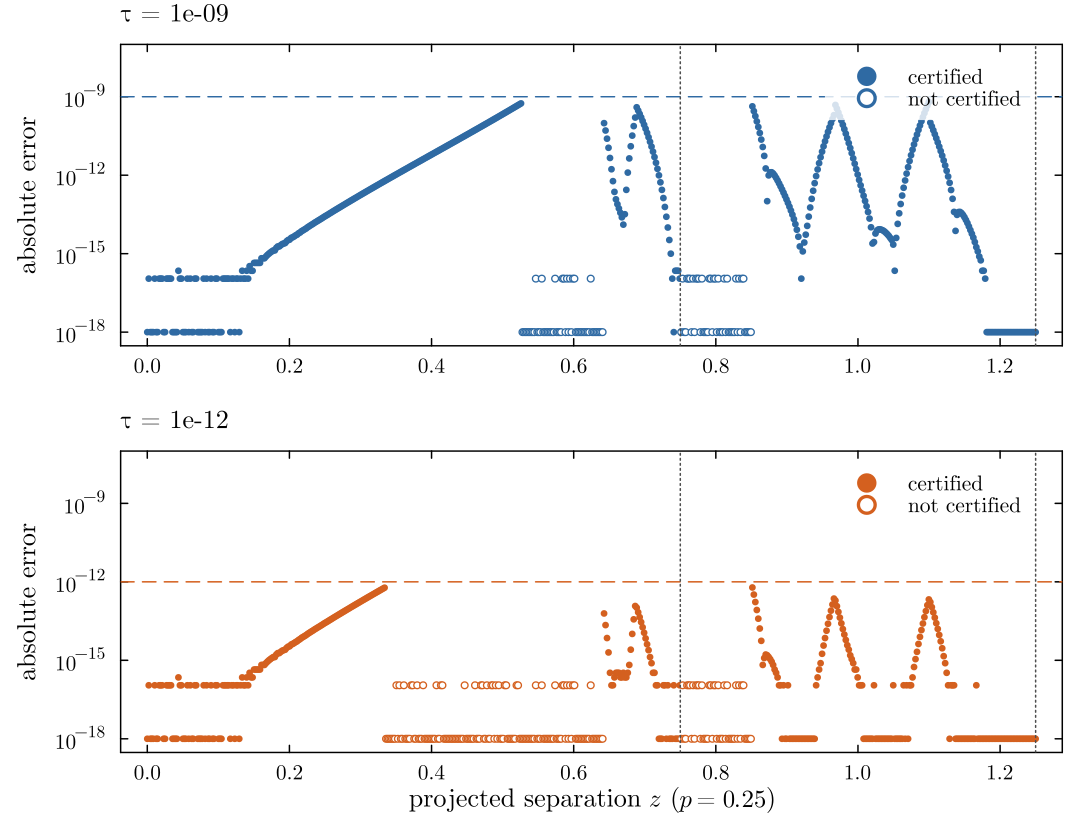

In [3]:
panels = map(((1e-9, COLORS.series), (1e-12, COLORS.limb))) do (τ, col)
    r = results[(0.25, τ)]
    e = max.(r.err, 1e-18)
    pl = plot(ylabel = "absolute error", yscale = :log10, ylims = (3e-19, 1e-7), yticks = 10.0 .^ (-18:3:-9),
              legend = :topright, title = "τ = $(sci(τ, 1))", titlelocation = :left)
    scatter!(pl, z[r.cert], e[r.cert], ms = 2.5, msw = 0, color = col, label = "certified")
    scatter!(pl, z[.!r.cert], e[.!r.cert], ms = 2.5, color = :white, msc = col, msw = 0.8, label = "not certified")
    hline!(pl, [τ], color = col, ls = :dash, lw = 1, label = "")
    vline!(pl, [0.75, 1.25], color = :gray30, ls = :dot, lw = 1, label = "")
end
xlabel!(panels[2], L"projected separation $z$ ($p = 0.25$)")
plt = plot(panels..., layout = (2, 1), link = :x, size = (720, 560))
plt

The dashed lines mark the tolerance, the dotted lines second contact $1 - p$ and first contact
$1 + p$; samples with zero error are drawn at $10^{-18}$. The samples that cannot be certified
lie in the innermost limb pieces, inside and around second contact, where the expansions
converge slowly; they are computed by quadrature, to rounding accuracy.

## 2. An enclosure of the exact flux

`occult_interval` evaluates the interior series in interval arithmetic, with the exact
rational table of its coefficients, and widens the result by the bound of Theorem 2. The
interval therefore contains the exact flux, whatever the rounding. We check it against
60-digit values:

In [4]:
rows = []
for p in (0.02, 0.1), zi in (0.0, 0.5, 0.8)
    I = occult_interval(zi, p, law)
    ref = setprecision(BigFloat, 200) do
        occult(big(zi), big(p), lawb; series_tol = 0)
    end
    push!(rows, (p, zi, @sprintf("[%.17f, %.17f]", inf(I), sup(I)), sci(diam(I)), inf(I) <= ref <= sup(I) ? "yes" : "NO"))
end
table(["p", "z", "enclosure of F", "width", "contains the 60-digit value"], rows)

p,z,enclosure of F,width,contains the 60-digit value
0.02,0.0,"[0.99953923719290183, 0.99953923719290216]",3.3e-16,yes
0.02,0.5,"[0.99956139186427995, 0.99956139186428028]",3.3e-16,yes
0.02,0.8,"[0.99960924398483042, 0.99960924398483075]",3.3e-16,yes
0.1,0.0,"[0.98849062903541718, 0.98849062903541751]",3.3e-16,yes
0.1,0.5,"[0.98904925143849254, 0.98904925143849309]",5.6e-16,yes
0.1,0.8,"[0.99027493003975753, 0.99027493061971861]",5.8e-10,yes


Near the centre the width is that of the rounding errors, a few units of $10^{-16}$; towards
$z_c$ it is dominated by the truncation bound (here $5.8 \times 10^{-10}$ at $z = 0.8$, $p = 0.1$),
which the enclosure includes so that it holds for the exact flux, not only for the series.

## 3. Theorem 2 at work

The interior series $S_M$ truncated at order $M = 11$, against the exact disk mean, both in
`BigFloat`, for the exponent $\gamma = 1/2$ (the $\mu^1$ term) and $p = 0.1$. The bound
$B_M(z, p)$ of Theorem 2 is closed-form and one-sided:

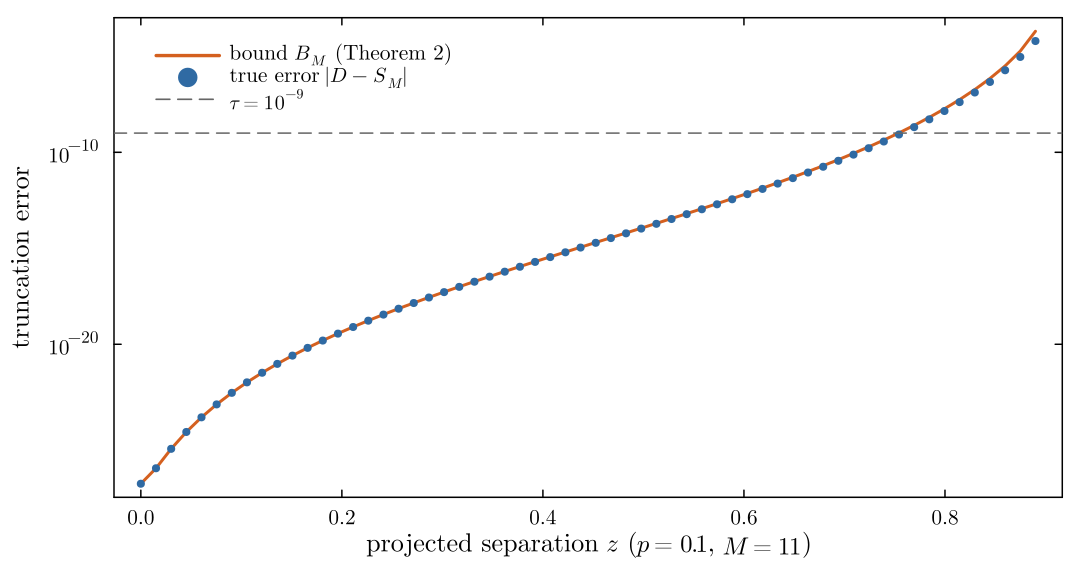

In [5]:
errors, bounds = setprecision(BigFloat, 200) do
    p, γ = big"0.1", big"0.5"
    A = series_table(γ, 11)
    zz = big.(range(0, 0.89, length = 60))
    S(z) = (w = 1 - z^2; w^γ * sum(sum(A[j+1, q+1] * p^(2q) for q in 0:11) * (1 / w)^j for j in 0:11))
    D(z) = blocked_flux(z, p, γ; series_tol = 0) / (big(π) * p^2)
    Float64.(abs.(D.(zz) .- S.(zz))), Float64.(series_bound.(zz, p, γ, 11))
end
zz = range(0, 0.89, length = 60)
plt = plot(xlabel = L"projected separation $z$ ($p = 0.1$, $M = 11$)", ylabel = "truncation error",
           yscale = :log10, legend = :topleft, size = (720, 380))
plot!(plt, zz, bounds, color = COLORS.limb, lw = 2, label = L"bound $B_M$ (Theorem 2)")
scatter!(plt, zz, errors, color = COLORS.series, ms = 3, msw = 0, label = L"true error $|D - S_M|$")
hline!(plt, [1e-9], color = :gray40, ls = :dash, lw = 1, label = L"\tau = 10^{-9}")
plt

The bound follows the true error closely over twenty orders of magnitude, so the cut $z_c$
where it reaches $\tau$ wastes little of the range of the series:

In [6]:
table(["z", "true error", "bound", "error / bound"],
      [(@sprintf("%.2f", zz[i]), sci(errors[i]), sci(bounds[i]), @sprintf("%.3f", errors[i] / bounds[i])) for i in (1, 20, 40, 52, 60)])

z,true error,bound,error / bound
0.00,5.4e-28,5.4e-28,0.998
0.29,2.7e-18,2.8e-18,0.982
0.59,3.6e-13,3.9e-13,0.924
0.77,2.0e-09,2.5e-09,0.807
0.89,6.2e-05,2.0e-04,0.310


## 4. References of your own

Everything is generic in the number type. With `BigFloat`, the series order $M$ and the
tolerance are raised together until the result no longer changes:

In [7]:
rows = []
setprecision(BigFloat, 256) do
    lb = Power2(big"0.6", big"0.6")
    prev = big(0)
    for (M, τ) in ((11, 1e-9), (21, 1e-20), (41, 1e-40), (61, 1e-60))
        v = occult(big"0.5", big"0.1", lb; series_tol = τ, M = M)
        push!(rows, (M, sci(τ, 1), "`" * string(v)[1:42] * "…`", prev == 0 ? "—" : sci(Float64(abs(v - prev)))))
        prev = v
    end
end
table(["M", "series_tol", "F(z = 0.5), power-2 law, p = 0.1", "change"], rows)

M,series_tol,"F(z = 0.5), power-2 law, p = 0.1",change
11,1e-09,0.9889845552077373592333728413326672929801…,—
21,1e-20,0.9889845552077374722054204435701489420744…,1.1e-16
41,1e-40,0.9889845552077374722054205400368375651838…,9.6e-26
61,1e-60,0.9889845552077374722054205400368375651838…,3.5e-43


## What you learned

- the default `occult` carries a proven bound in the interior and $\sim 10^{-15}$ at the limb;
- `occult_certified` extends the proof to the limb and tells you which samples carry it;
- `occult_interval` encloses the exact flux including rounding errors;
- the bound of Theorem 2 is tight, and `BigFloat` gives references to any precision.

**Next:** [J4 · Photodynamics](J4_photodynamics.ipynb), or
[J6 · The limb integral in Bartky's variable](J6_bartky.ipynb) for the limb rule behind the defaults.